<a href="https://colab.research.google.com/github/kazumah1/3Deeg/blob/main/3d_eeg_kazuma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3Deeg pipeline on Colab
Code lives in the repo (`n3d/`); this notebook only runs it. Everything persistent (data, checkpoints, the compiled PVCNN ops) goes to Drive under `MyDrive/3deeg/`, so a disconnect costs at most the steps since the last checkpoint. Re-run cell 1 after every new runtime.

Order: 1 setup, 2 data (once), 3 encoder overfit check, 4 full encoder, 5 diagnostics and baselines, 6 PVCNN build check, 7 diffusion overfit check, 8 full diffusion (expensive).

## 1. Setup (every new runtime)

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, subprocess
BRANCH = 'colab-pipeline'
os.environ.update({
    'N3D_DATA': '/content/drive/MyDrive/3deeg/data/neuro-3d',
    'N3D_RUNS': '/content/drive/MyDrive/3deeg/runs',
    'N3D_UPSTREAM': '/content/n3d_cache',
    'TORCH_EXTENSIONS_DIR': '/content/drive/MyDrive/3deeg/torch_extensions',
})
import torch
if not torch.cuda.is_available():
    print('WARNING: CPU-only runtime. Runtime > Change runtime type > GPU, then re-run this cell. '
          'Encoder training is ~50x slower on CPU and PVCNN cannot run at all.')
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader
%cd /content
!rm -rf /content/3deeg && git clone -q -b $BRANCH https://github.com/kazumah1/3deeg /content/3deeg
%cd /content/3deeg
!git log --oneline -1
!pip -q install -r requirements-colab.txt
from n3d import viz

Mounted at /content/drive
Tesla T4, 15360 MiB
/content
/content/3deeg
12104f6 (HEAD -> colab-pipeline, origin/colab-pipeline) Add model-free EEG sanity checks: evoked GFP, repetition reliability, colour probe


In [ ]:
from pathlib import Path

folder = Path('/content/drive/MyDrive/3deeg/runs/enc_sub01')
print('Files:', [p.name for p in folder.iterdir()])
print('Encoder checkpoint exists:', (folder / 'best.pt').exists())

Files: ['config.json', 'metrics.jsonl', 'snapshots', 'best.pt', 'last_prev.pt', 'last.pt', 'diagnostics.json', 'embeddings.npz']
Encoder checkpoint exists: True


In [6]:
!python -m n3d.encoder embed --run enc_sub01

/content/n3d_cache/neuro-3D-277b9cab95/eeg_data_process/extract_eeg_feature.py:36: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=1)
wrote /content/drive/MyDrive/3deeg/runs/enc_sub01/embeddings.npz: ['test_avg_cat', 'test_avg_color', 'test_avg_color_logits', 'test_avg_f_a', 'test_avg_f_g', 'test_avg_obj', 'test_avg_shape_logits', 'test_avg_sub', 'test_trial_cat', 'test_trial_color', 'test_trial_color_logits', 'test_trial_f_a', 'test_trial_f_g', 'test_trial_obj', 'test_trial_shape_logits', 'test_trial_sub', 'train_avg_cat', 'train_avg_color', 'train_avg_color_logits', 'train_avg_f_a', 'train_avg_f_g', 'train_avg_obj', 'train_avg_shape_logits', 'train_avg_sub', 'train_trial_cat', 'train_trial_color', 'train_trial_color_logits', 'train_trial_f_a', 'train_trial_f_g', 'trai

In [7]:
import os
import numpy as np
from pathlib import Path
from n3d.data import load_bundle, make_splits
from n3d.probe import bin_means, averaged

b = load_bundle(participants=("sub01",))
splits = make_splits(b)

# Pick 12 categories (2 held-out objects each = 24 objects).
# This is for visualization, not statistical inference.
chosen_cats = np.linspace(
    0, len(b.categories) - 1, 12, dtype=int
)
test_ids = splits["test"]
ids = test_ids[
    np.isin(b.obj_cat[test_ids], chosen_cats)
]

# Static EEG: 400-900 ms, five 100-ms bins.
# Static sampling rate = 250 Hz.
raw = bin_means(
    b.stat[:, :, 100:225], 5
).astype(np.float32)

# Normalize using training trials only.
train_mask = np.isin(
    b.trial_obj, splits["train"]
)
mu = raw[train_mask].mean(axis=0)
sd = raw[train_mask].std(axis=0) + 1e-6
raw = (raw - mu) / sd

# Average the four test repetitions per object.
X_eeg, _, _, obj_ids = averaged(raw, b, ids)
assert np.array_equal(obj_ids, ids)

# Load the trained encoder's held-out embeddings.
path = Path(os.environ["N3D_RUNS"]) / \
    "enc_sub01/embeddings.npz"

with np.load(path) as z:
    lookup = {
        int(o): i
        for i, o in enumerate(z["test_avg_obj"])
    }
    X_encoder = np.stack([
        z["test_avg_f_g"][lookup[int(o)]]
        for o in obj_ids
    ])

X_clip = b.clip_video[obj_ids]
cats = b.obj_cat[obj_ids]

print("Objects:", len(obj_ids))
print("Raw EEG:", X_eeg.shape)
print("Encoder:", X_encoder.shape)
print("CLIP:", X_clip.shape)


Objects: 24
Raw EEG: (24, 320)
Encoder: (24, 1024)
CLIP: (24, 1024)


## 2. Data (once; ~1.1 GB for sub01, kept on Drive)
Add participants later with `--participants sub02 sub03 ...`; already-packed files are skipped.

In [ ]:
!python -m n3d.download --participants sub01

download  EEGdata/sub01.zip

EEGdata/sub01.zip: downloading bytes:  48% 340M/712M [00:02<00:01, 275MB/s, 26.7MB/s  ]
EEGdata/sub01.zip: downloading bytes:  80% 712M/890M [00:03<00:00, 391MB/s, 61.5MB/s  ]
EEGdata/sub01.zip: reconstructing file:  66% 469M/712M [00:04<00:01, 133MB/s, 12.4MB/s  ]
EEGdata/sub01.zip: downloading bytes: 100% 712M/712M [00:06<00:00, 105MB/s, 61.9MB/s  ]
EEGdata/sub01.zip: reconstructing file: 100% 712M/712M [00:06<00:00, 105MB/s, 54.0MB/s  ]
packed    sub01_eeg.npz
download  point_cloud_simple.zip

point_cloud_simple.zip: downloading bytes:  90% 79.4M/88.0M [00:02<00:00, 63.1MB/s, 6.22MB/s  ]
point_cloud_simple.zip: downloading bytes: 100% 87.9M/87.9M [00:02<00:00, 31.6MB/s, 8.02MB/s  ]
point_cloud_simple.zip: reconstructing file: 100% 88.0M/88.0M [00:02<00:00, 31.6MB/s, 8.23MB/s  ]
packed    geometry_point_cloud_simple.npy
download  point_cloud.zip

point_cloud.zip: downloading bytes: 100% 102M/102M [00:02<00:00, 80.7MB/s, 9.11MB/s  ] 
point_cloud.zip: downl

## 3. Encoder overfit check (4 categories, ~1-2 min on GPU)
The pass condition is `trainset_shape_top1` climbing toward 1.0 (the model can memorise its own training objects). Val has only 4 objects here, so its accuracy moves in steps of 0.25 and is not the check.

In [ ]:
!python -m n3d.encoder train --run enc_tiny --tiny --epochs 60 --batch-size 32 --restart
viz.curves('enc_tiny', ['train_loss', 'trainset_shape_top1', 'val_shape_top1']).show()

/content/n3d_cache/neuro-3D-277b9cab95/eeg_data_process/extract_eeg_feature.py:36: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=1)
ep   0 loss 4.537 | trainset shape@1 0.071 | val shape@1 0.000 @5 0.000 nll 4.132 retr@1 0.000 | 3.0s
ep   1 loss 4.099 | trainset shape@1 0.286 | val shape@1 0.250 @5 0.750 nll 4.111 retr@1 0.500 | 0.1s
ep   2 loss 2.505 | trainset shape@1 0.000 | val shape@1 0.000 @5 0.000 nll 4.265 retr@1 0.250 | 0.1s
ep   3 loss 1.844 | trainset shape@1 0.000 | val shape@1 0.000 @5 0.000 nll 4.278 retr@1 0.250 | 0.1s
ep   4 loss 1.776 | trainset shape@1 0.250 | val shape@1 0.250 @5 0.500 nll 4.180 retr@1 0.250 | 0.1s
ep   5 loss 1.699 | trainset shape@1 0.250 | val shape@1 0.250 @5 1.000 nll 4.072 retr@1 0.250 | 0.1s
ep   6 loss 1.608 | trainset shape

## 4. Full encoder, sub01 (upstream recipe: 200 epochs)
Resumable: re-run the same cell after a disconnect. Selection is on val (variant 07); test is only reported.

In [4]:
# Full single-subject encoder.
# Resumes from the existing checkpoint when available.
!python -m n3d.encoder train \
    --run enc_sub01 \
    --participants sub01 \
    --epochs 200

/content/n3d_cache/neuro-3D-277b9cab95/eeg_data_process/extract_eeg_feature.py:36: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=1)
resumed at epoch 200 (best val shape_nll 4.1993)
done. best val shape_nll = 4.1993; checkpoints in /content/drive/MyDrive/3deeg/runs/enc_sub01


## 5. Failure-point diagnostics and reference baselines (cheap)
* `diagnose`: averaged vs single-trial EEG, each stream zeroed, shuffled EEG, noise sweep, within-category 2AFC, within-category shape probe.
* `baselines`: random / same-category / category-medoid / oracle-nearest Chamfer, plus classify-then-template and retrieve-then-copy from the encoder. Any generator must beat classify-then-template to claim EEG-driven shape.

In [ ]:
!python -m n3d.encoder diagnose --run enc_sub01
!python -m n3d.encoder embed --run enc_sub01
!python -m n3d.baselines --run baselines_sub01 --encoder-run enc_sub01

/content/n3d_cache/neuro-3D-277b9cab95/eeg_data_process/extract_eeg_feature.py:36: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=1)
chance: shape@1 0.014  shape@5 0.069  inst@1 0.007
test_repeats_averaged          shape@1 0.042 (p=0.016)  shape@5 0.194 (p=6.6e-07)  nll 4.106  retr@1 0.049  inst@1 0.021
test_single_trial              shape@1 0.033 (p=0.00059)  shape@5 0.113 (p=9.5e-05)  nll 4.303  retr@1 0.026  inst@1 0.019
dynamic_only (static=0)        shape@1 0.028 (p=0.14)  shape@5 0.090 (p=0.2)  nll 4.368  retr@1 0.035  inst@1 0.000
static_only (dynamic=0)        shape@1 0.042 (p=0.016)  shape@5 0.174 (p=2e-05)  nll 4.126  retr@1 0.021  inst@1 0.007
no_eeg (both=0)                shape@1 0.014 (p=0.6)  shape@5 0.069 (p=0.55)  nll 4.409  retr@1 0.014  inst@1 0.007


## 6. PVCNN build check (GPU; first time 3-8 min, cached on Drive afterwards)

In [ ]:
!python -c "from n3d.upstream import pvcnn2_class; pvcnn2_class(); print('PVCNN ops OK')"


## 7. Diffusion overfit check (8 training objects)
Generated clouds should converge to the training shapes; val_cd here is on those same objects.

In [ ]:
!python -m n3d.diffusion train --run dm_tiny --encoder-run enc_sub01 --tiny --max-steps 3000 --batch-size 8 --eval-every 500 --n-eval 8 --restart
viz.curves('dm_tiny', ['loss', 'val_cd']).show()
viz.show_samples('dm_tiny', k=3)

In [10]:

summary = []

for label, run in MODELS.items():
    folder = SESSION / "after" / run

    evaluation = json.loads(
        (folder / "eval_train_k1_s100.json").read_text()
    )["summary"]

    swap = json.loads(
        (folder / "swap_train_s100.json").read_text()
    )

    own_cd = swap["own"]["cd_to_own_gt"]
    zero_cd = swap["zeros"]["cd_to_own_gt"]

    summary.append({
        "model": label,
        "objects": evaluation["n_objects"],
        "train_chamfer": evaluation["cd_mean_over_samples"],
        "train_fscore": evaluation["f@0.02_mean"],
        "matched_eeg_cd": own_cd,
        "zero_eeg_cd": zero_cd,
        "zero_minus_matched": zero_cd - own_cd,
        "other_category_follows_donor":
            swap["other_category"].get(
                "follows_donor_frac"
            ),
    })

table = pd.DataFrame(summary)
display(table)

table.to_csv(
    SESSION / "comparison_corrected.csv",
    index=False
)


NameError: name 'MODELS' is not defined

## 8. Full diffusion, sub01 (expensive)
Upstream trains ~100k steps at batch 48. Check `sec_per_step` in the log after a few hundred steps and estimate cost before letting it run. Lower `--batch-size` if the GPU runs out of memory.

In [ ]:
!python -m n3d.diffusion train --run dm_sub01 --encoder-run enc_sub01 --max-steps 100000

### Evaluate and swap test

In [ ]:
!python -m n3d.diffusion sample --run dm_sub01 --eval-split test --samples 5 --steps 100
!python -m n3d.diffusion swap --run dm_sub01 --eval-split test --steps 100
viz.show_samples('dm_sub01', file='pred_test_k5_s100.npz', k=4)

### Cheap comparison runs (PointNet denoiser; Branch A/B)
Same data and harness; swap one factor at a time.

In [ ]:
# conditioning: concat vs FiLM, same denoiser
!python -m n3d.diffusion train --run pn_concat --encoder-run enc_sub01 --denoiser pointnet --cond-mode concat --max-steps 30000
!python -m n3d.diffusion train --run pn_film --encoder-run enc_sub01 --denoiser pointnet --cond-mode film --max-steps 30000
# what the decoder could do with a perfect encoder, and with category alone
!python -m n3d.diffusion train --run pn_oracle_clip --cond-source clip --denoiser pointnet --max-steps 30000
!python -m n3d.diffusion train --run pn_category --cond-source category --denoiser pointnet --max-steps 30000

In [ ]:
# 1. PointNet runs on test, comparable to dm_sub01 and the baselines
for r in ['pn_concat', 'pn_film', 'pn_oracle_clip', 'pn_category']:
    !python -m n3d.diffusion sample --run {r} --eval-split test --samples 5 --steps 100

# 2. 8-object overfit check, PVCNN vs PointNet (~1 h total)
!python -m n3d.diffusion train --run tiny_pv --encoder-run enc_sub01 --tiny --max-steps 5000 --batch-size 8 --eval-every 500 --n-eval 8 --restart
!python -m n3d.diffusion train --run tiny_pn --encoder-run enc_sub01 --tiny --denoiser pointnet --max-steps 5000 --batch-size 8 --eval-every 500 --n-eval 8 --restart
viz.show_samples('tiny_pv', k=2); viz.show_samples('tiny_pn', k=2)

In [ ]:
!python -m n3d.baselines --run baselines_sub01 --encoder-run enc_sub01
for r in ['pn_concat', 'pn_film']:
    !python -m n3d.diffusion swap --run {r} --eval-split test --steps 100

In [ ]:
for r in ['dm_sub01', 'pn_concat', 'pn_film', 'pn_category', 'pn_oracle_clip']:
    !python -m n3d.identify --run {r} --file pred_test_k5_s100.npz

In [ ]:
# 1. More subjects (download once)
!python -m n3d.download --participants sub02 sub03 sub04 sub05

# 2. Encoder runs, 60 epochs (val NLL already selects the best epoch)
!python -m n3d.encoder train --run enc_multi5 --participants sub01 sub02 sub03 sub04 sub05 --epochs 60
!python -m n3d.encoder train --run enc_sub01_dyn --zero-stream stat --epochs 60
!python -m n3d.encoder train --run enc_sub01_s1 --epochs 60 --seed 1
!python -m n3d.encoder train --run enc_sub01_s2 --epochs 60 --seed 2

# 3. Diagnostics for each
for r in ['enc_multi5', 'enc_sub01_dyn', 'enc_sub01_s1', 'enc_sub01_s2']:
    !python -m n3d.encoder diagnose --run {r}

In [ ]:
!python -m n3d.encoder embed --run enc_sub01_s1
!python -m n3d.encoder embed --run enc_sub01_s2
!python -m n3d.probe ensemble --run ens_sub01 --encoder-runs enc_sub01 enc_sub01_s1 enc_sub01_s2
!python -m n3d.probe linear --run lin_sub01
!python -m n3d.probe linear --run lin_sub01_stat --streams stat
!python -m n3d.probe linear --run lin_multi5 --participants sub01 sub02 sub03 sub04 sub05

/content/n3d_cache/neuro-3D-277b9cab95/eeg_data_process/extract_eeg_feature.py:36: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=1)
wrote /content/drive/MyDrive/3deeg/runs/enc_sub01_s1/embeddings.npz: ['test_avg_cat', 'test_avg_color', 'test_avg_color_logits', 'test_avg_f_a', 'test_avg_f_g', 'test_avg_obj', 'test_avg_shape_logits', 'test_avg_sub', 'test_trial_cat', 'test_trial_color', 'test_trial_color_logits', 'test_trial_f_a', 'test_trial_f_g', 'test_trial_obj', 'test_trial_shape_logits', 'test_trial_sub', 'train_avg_cat', 'train_avg_color', 'train_avg_color_logits', 'train_avg_f_a', 'train_avg_f_g', 'train_avg_obj', 'train_avg_shape_logits', 'train_avg_sub', 'train_trial_cat', 'train_trial_color', 'train_trial_color_logits', 'train_trial_f_a', 'train_trial_f_g', 't

In [ ]:
!python -m n3d.probe timecourse --run tc_multi5 --participants sub01 sub02 sub03 sub04 sub05 --stream stat --window-ms 100 --step-ms 50
!python -m n3d.probe timecourse --run tc_multi5 --participants sub01 sub02 sub03 sub04 sub05 --stream dyn --window-ms 500 --step-ms 250

stat: 250 samples @ 250 Hz, window 100.0 ms, step 50.0 ms, C 0.001
     0-   100 ms  top1 0.011  top5 0.078 (p=0.21)  nll 4.281
    48-   148 ms  top1 0.021  top5 0.076 (p=0.25)  nll 4.276
    96-   196 ms  top1 0.008  top5 0.071 (p=0.46)  nll 4.279
   144-   244 ms  top1 0.011  top5 0.072 (p=0.41)  nll 4.278
   192-   292 ms  top1 0.011  top5 0.081 (p=0.14)  nll 4.274
   240-   340 ms  top1 0.018  top5 0.089 (p=0.027)  nll 4.273
   288-   388 ms  top1 0.025  top5 0.090 (p=0.02)  nll 4.266
   336-   436 ms  top1 0.014  top5 0.100 (p=0.0014)  nll 4.255
   384-   484 ms  top1 0.025  top5 0.111 (p=2.8e-05)  nll 4.250
   432-   532 ms  top1 0.015  top5 0.101 (p=0.00089)  nll 4.251
   480-   580 ms  top1 0.024  top5 0.111 (p=2.8e-05)  nll 4.250
   528-   628 ms  top1 0.025  top5 0.106 (p=0.00022)  nll 4.253
   576-   676 ms  top1 0.018  top5 0.107 (p=0.00013)  nll 4.253
   624-   724 ms  top1 0.014  top5 0.090 (p=0.02)  nll 4.258
   672-   772 ms  top1 0.015  top5 0.104 (p=0.00036)  nll 4.2

In [ ]:
!python -m n3d.primprobe --run prim_multi5 --participants sub01 sub02 sub03 sub04 sub05

fitting primitives to all objects ...
ridge alpha 300000; test rows 720
target               eeg_ridge  eeg_via_category   oracle_category
e1                       0.003             0.004             0.453
e2                       0.005             0.009             0.545
e3                       0.008             0.010             0.700
log_e2_e1                0.006             0.012             0.569
log_e3_e1                0.007             0.009             0.747
k4_vol1                  0.003             0.006             0.449
k4_vol2                  0.000             0.003             0.392
k4_vol3                  0.003             0.006             0.340
k4_vol4                  0.004             0.004             0.320
k4_spread                0.004             0.004             0.437
MEAN                     0.004             0.007             0.495
null mean R^2 -0.000, 95th pct 0.001; eeg_ridge p = 0.0196
  sub01: eeg_ridge mean R^2 0.005
  sub02: eeg_ridge mean R^2 0.0

In [ ]:
!python -m n3d.download --participants sub06 sub07 sub08 sub09 sub10
# windows chosen on sub01-05; confirm on sub06-10
!python -m n3d.probe linear --run lin_s610_full --participants sub06 sub07 sub08 sub09 sub10
!python -m n3d.probe linear --run lin_s610_crop --participants sub06 sub07 sub08 sub09 sub10 --dyn-ms 0 1000 --stat-ms 240 920

have      EEGdata/sub06.zip (712 MB)
have      EEGdata/sub07.zip (712 MB)
have      EEGdata/sub08.zip (712 MB)
have      EEGdata/sub09.zip (712 MB)
have      EEGdata/sub10.zip (712 MB)
done: /content/drive/MyDrive/3deeg/data/neuro-3d/packed
features 3520  train rows 5040  val 360  test 720
C 0.0001: train top1 0.141 | val top1 0.014 top5 0.097 nll 4.266
C 0.0003: train top1 0.217 | val top1 0.011 top5 0.089 nll 4.269
C 0.001: train top1 0.341 | val top1 0.017 top5 0.072 nll 4.307
C 0.003: train top1 0.511 | val top1 0.011 top5 0.069 nll 4.417
C 0.01: train top1 0.773 | val top1 0.019 top5 0.078 nll 4.687
C 0.03: train top1 0.953 | val top1 0.022 top5 0.078 nll 5.145
test all    n  720  top1 0.026 (p=0.0068)  top5 0.115 (p=5.3e-06)  nll 4.265
test sub06  n  144  top1 0.035 (p=0.051)  top5 0.118 (p=0.023)  nll 4.261
test sub07  n  144  top1 0.014 (p=0.6)  top5 0.167 (p=5.8e-05)  nll 4.245
test sub08  n  144  top1 0.021 (p=0.32)  top5 0.062 (p=0.68)  nll 4.287
test sub09  n  144  top1 0.0

In [ ]:
!git -C /content/3deeg pull -q
!python -m n3d.sanity --run sanity_s1_10 --participants sub01 sub02 sub03 sub04 sub05 sub06 sub07 sub08 sub09 sub10

stat: GFP top peaks at [988.0, 992.0, 996.0] ms; mean GFP 100-200 ms / 0-50 ms = 0.81
dyn: GFP top peaks at [460.0, 470.0, 480.0] ms; mean GFP 100-200 ms / 0-50 ms = 0.69
reliability (train objects, rep A vs rep B, within subject, n_pairs 5040):
  same - diff object r      +0.0036 (null p95 +0.0047, p=0.114)
  same-cat - diff-cat r     +0.0009 (null p95 +0.0015, p=0.189)
  rep identification        0.0028 (chance 0.0020, p=0.139)
  stat     0-  100 ms  same-diff -0.0033 (p=0.75)  cat -0.0007 (p=0.69)
  stat   100-  200 ms  same-diff -0.0052 (p=0.9)  cat +0.0025 (p=0.059)
  stat   200-  300 ms  same-diff -0.0055 (p=0.94)  cat +0.0020 (p=0.078)
  stat   300-  400 ms  same-diff +0.0042 (p=0.12)  cat +0.0051 (p=0.02)
  stat   400-  500 ms  same-diff +0.0100 (p=0.039)  cat +0.0070 (p=0.02)
  stat   500-  600 ms  same-diff +0.0124 (p=0.02)  cat +0.0066 (p=0.02)
  stat   600-  700 ms  same-diff +0.0151 (p=0.02)  cat +0.0078 (p=0.02)
  stat   700-  800 ms  same-diff +0.0154 (p=0.02)  cat +0.00

In [2]:

from pathlib import Path
import numpy as np

packed = Path("/content/drive/MyDrive/3deeg/data/neuro-3d/packed")

for i in range(1, 13):
    sub = f"sub{i:02d}"
    path = packed / f"{sub}_eeg.npz"

    if not path.exists():
        print(f"{sub}: MISSING")
        continue

    with np.load(path) as z:
        labels = z["label"].astype(str)
        print(
            sub,
            "trials:", len(labels),
            "objects:", len(np.unique(labels)),
            "static:", z["stat"].shape,
            "dynamic:", z["dyn"].shape,
        )


sub01 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub02 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub03 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub04 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub05 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub06 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub07 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub08 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub09 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub10 trials: 1728 objects: 720 static: (1728, 64, 250) dynamic: (1728, 64, 600)
sub11: MISSING
sub12: MISSING


In [3]:

# Download and pack the two missing participants.
# Existing packed geometry and CLIP features will be reused.
!python -m n3d.download --participants sub11 sub12


download  EEGdata/sub11.zip

EEGdata/sub11.zip: downloading bytes:  98% 702M/713M [00:05<00:00, 288MB/s, 55.3MB/s  ]
EEGdata/sub11.zip: reconstructing file:  36% 256M/713M [00:08<00:14, 31.3MB/s]
EEGdata/sub11.zip: downloading bytes: 100% 713M/713M [00:09<00:00, 72.0MB/s, 56.3MB/s  ]
EEGdata/sub11.zip: reconstructing file: 100% 713M/713M [00:09<00:00, 72.0MB/s, 55.9MB/s  ]
packed    sub11_eeg.npz
download  EEGdata/sub12.zip

EEGdata/sub12.zip: downloading bytes:  92% 656M/713M [00:03<00:00, 379MB/s, 54.5MB/s  ]
EEGdata/sub12.zip: downloading bytes:  80% 713M/891M [00:03<00:00, 346MB/s, 60.0MB/s  ]
EEGdata/sub12.zip: reconstructing file:  56% 402M/713M [00:04<00:02, 107MB/s, 6.15MB/s  ]
EEGdata/sub12.zip: downloading bytes: 100% 713M/713M [00:06<00:00, 115MB/s, 61.4MB/s  ]
EEGdata/sub12.zip: reconstructing file: 100% 713M/713M [00:06<00:00, 114MB/s, 57.7MB/s  ]
packed    sub12_eeg.npz
done: /content/drive/MyDrive/3deeg/data/neuro-3d/packed


In [5]:
import json
from pathlib import Path
import os

runs = Path(os.environ["N3D_RUNS"])
folder = runs / "enc_sub01"

records = [
    json.loads(line)
    for line in (folder / "metrics.jsonl").read_text().splitlines()
    if line.strip()
]
selected = [r for r in records if r.get("saved_best")]

assert selected, "No best-checkpoint record found"
r = selected[-1]

paper = {
    "shape_top1": 0.0591,
    "shape_top5": 0.1630,
    "color_top1": 0.3993,
}

print("Selected epoch:", r["epoch"])
print("\nMetric                Ours       Paper (12-subject mean)")

for metric, published in paper.items():
    ours = r.get(f"test_{metric}")
    if ours is not None:
        print(f"{metric:19} {ours:7.2%}    {published:7.2%}")

print("\nCLIP retrieval (different metric):")
for metric in ["retr_cat_top1", "retr_cat_top5"]:
    print(metric, r.get(f"test_{metric}"))

print("\nValidation NLL:", r.get("val_shape_nll"))
print("Train top-1:", r.get("trainset_shape_top1"))


Selected epoch: 38

Metric                Ours       Paper (12-subject mean)
shape_top1            4.17%      5.91%
shape_top5           20.14%     16.30%
color_top1           20.14%     39.93%

CLIP retrieval (different metric):
retr_cat_top1 0.05555555555555555
retr_cat_top5 0.1736111111111111

Validation NLL: 4.199290752410889
Train top-1: 0.998015873015873


In [8]:

from scipy.spatial import cKDTree

def correlation_rdm(X):
    X = np.asarray(X, dtype=np.float64)
    X = X - X.mean(axis=1, keepdims=True)
    X = X / np.maximum(
        np.linalg.norm(X, axis=1, keepdims=True),
        1e-12
    )
    D = np.clip(1 - X @ X.T, 0, 2)
    np.fill_diagonal(D, 0)
    return D

def cosine_rdm(X):
    X = np.asarray(X, dtype=np.float64)
    X = X / np.maximum(
        np.linalg.norm(X, axis=1, keepdims=True),
        1e-12
    )
    D = np.clip(1 - X @ X.T, 0, 2)
    np.fill_diagonal(D, 0)
    return D

D_eeg = correlation_rdm(X_eeg)
D_encoder = cosine_rdm(X_encoder)
D_clip = cosine_rdm(X_clip)

# Approximate symmetric squared Chamfer distance.
rng = np.random.default_rng(42)

clouds = [
    b.points[int(obj), rng.choice(
        b.points.shape[1], 256, replace=False
    )]
    for obj in obj_ids
]

trees = [cKDTree(p) for p in clouds]
n = len(clouds)
D_geometry = np.zeros((n, n), dtype=np.float32)

for i in range(n):
    for j in range(i + 1, n):
        d1 = trees[j].query(clouds[i], k=1)[0]
        d2 = trees[i].query(clouds[j], k=1)[0]
        cd = np.mean(d1**2) + np.mean(d2**2)
        D_geometry[i, j] = D_geometry[j, i] = cd

print("All dissimilarity matrices:", D_eeg.shape)


All dissimilarity matrices: (24, 24)


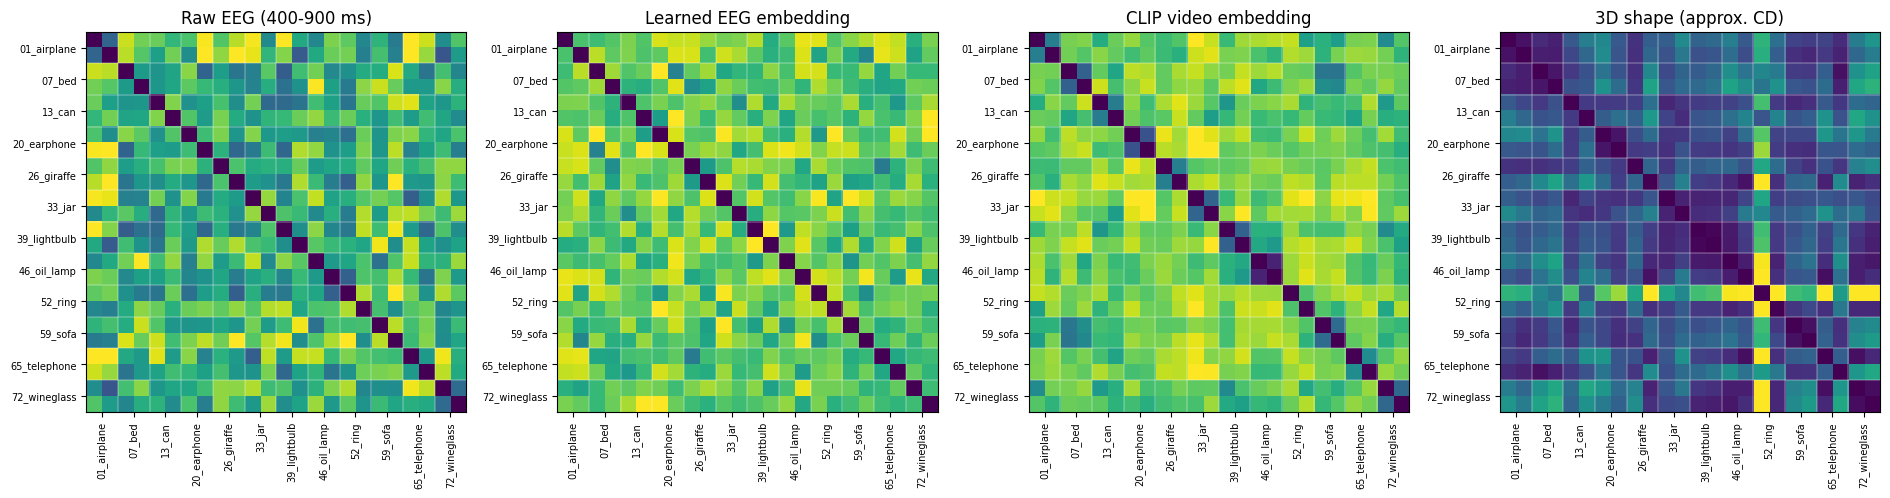


Spearman correlations with 3D geometry:
Raw EEG        : -0.094
EEG encoder    : -0.033
CLIP           : +0.185


In [9]:

import matplotlib.pyplot as plt
from scipy.stats import spearmanr

matrices = {
    "Raw EEG (400-900 ms)": D_eeg,
    "Learned EEG embedding": D_encoder,
    "CLIP video embedding": D_clip,
    "3D shape (approx. CD)": D_geometry,
}

unique_cats = np.unique(cats)
centers = [
    np.flatnonzero(cats == c).mean()
    for c in unique_cats
]
names = [b.categories[int(c)] for c in unique_cats]

fig, axes = plt.subplots(1, 4, figsize=(19, 5))

for ax, (title, D) in zip(axes, matrices.items()):
    vmax = np.percentile(
        D[np.triu_indices(len(D), 1)], 98
    )
    ax.imshow(D, cmap="viridis", vmin=0, vmax=vmax)

    ax.set_title(title)
    ax.set_xticks(centers, names, rotation=90, fontsize=7)
    ax.set_yticks(centers, names, fontsize=7)

    # Show category boundaries.
    for cut in np.flatnonzero(cats[1:] != cats[:-1]) + 1:
        ax.axvline(cut - 0.5, linewidth=0.3, color="white")
        ax.axhline(cut - 0.5, linewidth=0.3, color="white")

plt.tight_layout()
plt.show()

# Descriptive RSA correlations only.
tri = np.triu_indices(len(obj_ids), 1)

print("\nSpearman correlations with 3D geometry:")
for name, D in [
    ("Raw EEG", D_eeg),
    ("EEG encoder", D_encoder),
    ("CLIP", D_clip),
]:
    rho = spearmanr(
        D[tri], D_geometry[tri]
    ).statistic
    print(f"{name:15}: {rho:+.3f}")


In [11]:

from scipy.stats import spearmanr
import numpy as np

# Objects in the same category have dissimilarity 0.
# Objects in different categories have dissimilarity 1.
D_category = (
    cats[:, None] != cats[None, :]
).astype(float)

rdms = {
    "Raw EEG": D_eeg,
    "Learned EEG": D_encoder,
    "CLIP": D_clip,
    "3D geometry": D_geometry,
    "Category": D_category,
}

tri = np.triu_indices(len(cats), 1)

print("RDM similarity (Spearman rho)\n")

for source in ["Raw EEG", "Learned EEG"]:
    for target in ["Category", "CLIP", "3D geometry"]:
        rho = spearmanr(
            rdms[source][tri],
            rdms[target][tri]
        ).statistic

        print(f"{source:12} vs {target:12}: {rho:+.3f}")

# Geometry similarity among objects of the SAME category.
within = cats[tri[0]] == cats[tri[1]]

print("\nWithin-category pairs:", within.sum())

for source in ["Raw EEG", "Learned EEG", "CLIP"]:
    rho = spearmanr(
        rdms[source][tri][within],
        D_geometry[tri][within]
    ).statistic

    print(f"{source:12} vs within-category geometry: "
          f"{rho:+.3f}")


RDM similarity (Spearman rho)

Raw EEG      vs Category    : +0.014
Raw EEG      vs CLIP        : +0.013
Raw EEG      vs 3D geometry : -0.094
Learned EEG  vs Category    : -0.019
Learned EEG  vs CLIP        : +0.056
Learned EEG  vs 3D geometry : -0.033

Within-category pairs: 12
Raw EEG      vs within-category geometry: +0.469
Learned EEG  vs within-category geometry: -0.301
CLIP         vs within-category geometry: +0.573


In [ ]:
from google.colab import drive; drive.flush_and_unmount()